Coloured MNIST: ERM vs IRM

 Training ERM
Restart 0
step         train nll    train acc    test acc
0            0.71656      0.44542      0.58450     
100          0.39596      0.84992      0.10140     
200          0.38324      0.84998      0.10230     
300          0.37529      0.85014      0.10260     
400          0.37066      0.85054      0.10350     
500          0.36774      0.85074      0.10450     
Final train acc (mean/std across restarts so far):
0.85074 0.00000
Final test acc (mean/std across restarts so far):
0.10450 0.00000

Restart 1
step         train nll    train acc    test acc
0            0.72715      0.39434      0.63490     
100          0.39746      0.85054      0.09900     
200          0.38596      0.85052      0.09960     
300          0.37894      0.85068      0.10000     
400          0.37468      0.85074      0.10030     
500          0.37177      0.85084      0.10080     
Final train acc (mean/std across restarts so far):
0.85079 0.00005
Final test acc (m

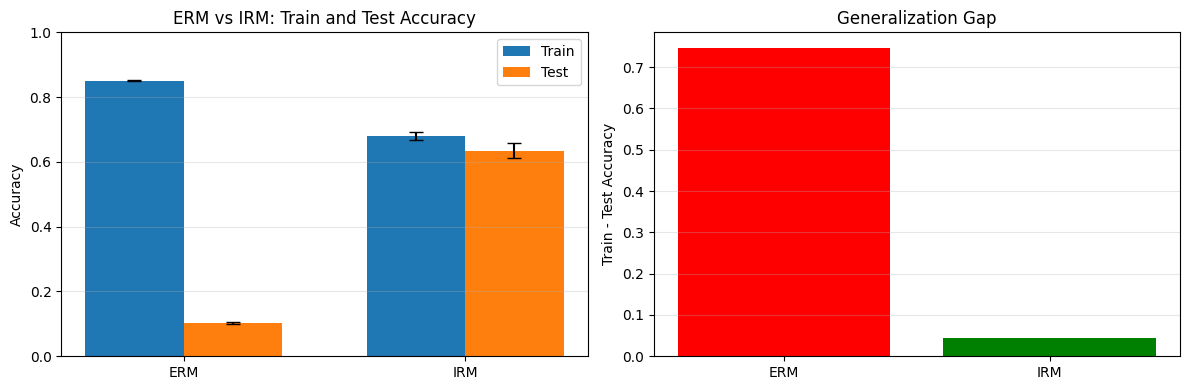

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets

import warnings
warnings.filterwarnings('ignore')

def relu(z):
    return np.maximum(0, z)

def relu_grad(z):
    return (z > 0).astype(np.float32)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def forward(X, W, V):
    Z = X @ W.T
    H = relu(Z)
    F = H @ V.T
    return Z, H, F

def mean_nll(logits, y):
    """Binary cross entropy with logits"""
    sig = sigmoid(logits)
    eps = 1e-7
    return -np.mean(y * np.log(sig + eps) + (1 - y) * np.log(1 - sig + eps))

def mean_accuracy(logits, y):
    preds = (logits > 0.).astype(np.float32)
    return np.mean(np.abs(preds - y) < 1e-2)


def penalty(logits, y):
    """IRM penalty"""
    sig = sigmoid(logits)
    grad_scale = np.mean(logits * (sig - y))
    return grad_scale ** 2

def compute_penalty_gradients(X, y, Z, H, F, W, V):
    B = X.shape[0]
    
    sig = sigmoid(F[:, 0])
    grad_scale = np.mean(F[:, 0] * (sig - y))
    d_grad_scale_dF = ((sig - y) + F[:, 0] * sig * (1 - sig)) / B
    dP_dF = 2 * grad_scale * d_grad_scale_dF
    dP_dF = dP_dF[:, None]
    
    dP_dV = dP_dF.T @ H
    dP_dH = dP_dF @ V
    dP_dZ = dP_dH * relu_grad(Z)
    dP_dW = dP_dZ.T @ X
    
    return dP_dW, dP_dV


def gradients_nll(X, y, Z, H, F, W, V):
    B = X.shape[0]
    
    sig = sigmoid(F[:, 0])
    dL_dF = (sig - y)[:, None]
    
    dL_dV = (dL_dF.T @ H) / B
    dL_dH = dL_dF @ V
    dL_dZ = dL_dH * relu_grad(Z)
    dL_dW = (dL_dZ.T @ X) / B
    
    return dL_dW, dL_dV


def make_environment(images, labels, e):
    images = images.reshape(-1, 28, 28)[:, ::2, ::2]
    labels = (labels < 5).astype(np.float32)
    labels = np.abs(labels - (np.random.rand(len(labels)) < 0.25).astype(np.float32))
    colors = np.abs(labels - (np.random.rand(len(labels)) < e).astype(np.float32))

    images_colored = np.stack([images, images], axis=1).astype(np.float32)
    colors_int = colors.astype(np.int64)
    channel_to_zero = 1 - colors_int
    idx = np.arange(len(images))
    images_colored[idx, channel_to_zero, :, :] = 0

    X = images_colored.reshape(len(images), -1).astype(np.float32) / 255.0
    y = labels

    return X, y


def train_erm(hidden_dim=256, l2_regularizer_weight=0.001, lr=0.001,
              n_restarts=10, steps=501):
    
    final_train_accs = []
    final_test_accs = []

    for restart in range(n_restarts):
        print(f"Restart {restart}")

        mnist = datasets.MNIST('~/datasets/mnist', train=True, download=True)
        mnist_train = (mnist.data[:50000].numpy(), mnist.targets[:50000].numpy())
        mnist_val = (mnist.data[50000:].numpy(), mnist.targets[50000:].numpy())

        rng_state = np.random.get_state()
        np.random.shuffle(mnist_train[0])
        np.random.set_state(rng_state)
        np.random.shuffle(mnist_train[1])

        envs = [
            make_environment(mnist_train[0][::2], mnist_train[1][::2], 0.2),
            make_environment(mnist_train[0][1::2], mnist_train[1][1::2], 0.1),
            make_environment(mnist_val[0], mnist_val[1], 0.9)
        ]
        
        X_train = np.vstack([envs[0][0], envs[1][0]])
        y_train = np.hstack([envs[0][1], envs[1][1]])
        X_test, y_test = envs[2]

        d = 2 * 14 * 14
        h = hidden_dim

        limit_W = np.sqrt(6.0 / (d + h))
        W = np.random.uniform(-limit_W, limit_W, (h, d)).astype(np.float32)

        limit_V = np.sqrt(6.0 / (h + 1))
        V = np.random.uniform(-limit_V, limit_V, (1, h)).astype(np.float32)

        m_W = np.zeros_like(W)
        m_V = np.zeros_like(V)
        v_W = np.zeros_like(W)
        v_V = np.zeros_like(V)
        beta1 = 0.9
        beta2 = 0.999
        eps = 1e-8

        print("step         train nll    train acc    test acc")

        for step in range(steps):

            Z_train, H_train, F_train = forward(X_train, W, V)
            train_nll = mean_nll(F_train[:, 0], y_train)
            train_acc = mean_accuracy(F_train[:, 0], y_train)
            
            Z_test, H_test, F_test = forward(X_test, W, V)
            test_acc = mean_accuracy(F_test[:, 0], y_test)

            dW_nll, dV_nll = gradients_nll(X_train, y_train, Z_train, H_train, F_train, W, V)

            total_grad_W = dW_nll + l2_regularizer_weight * 2 * W
            total_grad_V = dV_nll + l2_regularizer_weight * 2 * V

            m_W = beta1 * m_W + (1 - beta1) * total_grad_W
            m_V = beta1 * m_V + (1 - beta1) * total_grad_V
            v_W = beta2 * v_W + (1 - beta2) * (total_grad_W ** 2)
            v_V = beta2 * v_V + (1 - beta2) * (total_grad_V ** 2)

            m_W_hat = m_W / (1 - beta1 ** (step + 1))
            m_V_hat = m_V / (1 - beta1 ** (step + 1))
            v_W_hat = v_W / (1 - beta2 ** (step + 1))
            v_V_hat = v_V / (1 - beta2 ** (step + 1))

            W -= lr * m_W_hat / (np.sqrt(v_W_hat) + eps)
            V -= lr * m_V_hat / (np.sqrt(v_V_hat) + eps)

            if step % 100 == 0:
                print(f"{step:<12} {train_nll:<12.5f} {train_acc:<12.5f} {test_acc:<12.5f}")

        final_train_accs.append(train_acc)
        final_test_accs.append(test_acc)

        print(f"Final train acc (mean/std across restarts so far):")
        print(f"{np.mean(final_train_accs):.5f} {np.std(final_train_accs):.5f}")
        print(f"Final test acc (mean/std across restarts so far):")
        print(f"{np.mean(final_test_accs):.5f} {np.std(final_test_accs):.5f}")
        print()

    return final_train_accs, final_test_accs


def train_irm(hidden_dim=256, l2_regularizer_weight=0.001, lr=0.001,
              n_restarts=10, penalty_anneal_iters=100, penalty_weight=10000.0,
              steps=501):
    
    final_train_accs = []
    final_test_accs = []

    for restart in range(n_restarts):
        print(f"Restart {restart}")

        # Load MNIST
        mnist = datasets.MNIST('~/datasets/mnist', train=True, download=True)
        mnist_train = (mnist.data[:50000].numpy(), mnist.targets[:50000].numpy())
        mnist_val = (mnist.data[50000:].numpy(), mnist.targets[50000:].numpy())

        rng_state = np.random.get_state()
        np.random.shuffle(mnist_train[0])
        np.random.set_state(rng_state)
        np.random.shuffle(mnist_train[1])

        envs = [
            make_environment(mnist_train[0][::2], mnist_train[1][::2], 0.2),
            make_environment(mnist_train[0][1::2], mnist_train[1][1::2], 0.1),
            make_environment(mnist_val[0], mnist_val[1], 0.9)
        ]

        d = 2 * 14 * 14
        h = hidden_dim

        limit_W = np.sqrt(6.0 / (d + h))
        W = np.random.uniform(-limit_W, limit_W, (h, d)).astype(np.float32)

        limit_V = np.sqrt(6.0 / (h + 1))
        V = np.random.uniform(-limit_V, limit_V, (1, h)).astype(np.float32)

        m_W = np.zeros_like(W)
        m_V = np.zeros_like(V)
        v_W = np.zeros_like(W)
        v_V = np.zeros_like(V)
        beta1 = 0.9
        beta2 = 0.999
        eps = 1e-8

        print("step         train nll    train acc    train penalty test acc")

        for step in range(steps):
            env_nlls = []
            env_accs = []
            env_penalties = []

            for env_idx in range(3):
                X_env, y_env = envs[env_idx]
                Z, H, F = forward(X_env, W, V)

                nll = mean_nll(F[:, 0], y_env)
                acc = mean_accuracy(F[:, 0], y_env)
                pen = penalty(F[:, 0], y_env)

                env_nlls.append(nll)
                env_accs.append(acc)
                env_penalties.append(pen)

            train_nll = np.mean([env_nlls[0], env_nlls[1]])
            train_acc = np.mean([env_accs[0], env_accs[1]])
            train_penalty = np.mean([env_penalties[0], env_penalties[1]])
            test_acc = env_accs[2]

            pw = penalty_weight if step >= penalty_anneal_iters else 1.0

            total_grad_W = np.zeros_like(W)
            total_grad_V = np.zeros_like(V)

            for env_idx in [0, 1]:
                X_env, y_env = envs[env_idx]
                Z, H, F = forward(X_env, W, V)

                dW_nll, dV_nll = gradients_nll(X_env, y_env, Z, H, F, W, V)

                dW_penalty, dV_penalty = compute_penalty_gradients(
                    X_env, y_env, Z, H, F, W, V
                )

                total_grad_W += dW_nll + pw * dW_penalty
                total_grad_V += dV_nll + pw * dV_penalty

            total_grad_W /= 2.0
            total_grad_V /= 2.0

            total_grad_W += l2_regularizer_weight * 2 * W
            total_grad_V += l2_regularizer_weight * 2 * V

            if pw > 1.0:
                total_grad_W /= pw
                total_grad_V /= pw

            m_W = beta1 * m_W + (1 - beta1) * total_grad_W
            m_V = beta1 * m_V + (1 - beta1) * total_grad_V
            v_W = beta2 * v_W + (1 - beta2) * (total_grad_W ** 2)
            v_V = beta2 * v_V + (1 - beta2) * (total_grad_V ** 2)

            m_W_hat = m_W / (1 - beta1 ** (step + 1))
            m_V_hat = m_V / (1 - beta1 ** (step + 1))
            v_W_hat = v_W / (1 - beta2 ** (step + 1))
            v_V_hat = v_V / (1 - beta2 ** (step + 1))

            W -= lr * m_W_hat / (np.sqrt(v_W_hat) + eps)
            V -= lr * m_V_hat / (np.sqrt(v_V_hat) + eps)

            if step % 100 == 0:
                print(f"{step:<12} {train_nll:<12.5f} {train_acc:<12.5f} "
                      f"{train_penalty:<13.5f} {test_acc:<12.5f}")

        final_train_accs.append(train_acc)
        final_test_accs.append(test_acc)

        print(f"Final train acc (mean/std across restarts so far):")
        print(f"{np.mean(final_train_accs):.5f} {np.std(final_train_accs):.5f}")
        print(f"Final test acc (mean/std across restarts so far):")
        print(f"{np.mean(final_test_accs):.5f} {np.std(final_test_accs):.5f}")
        print()

    return final_train_accs, final_test_accs


if __name__ == "__main__":
    print("Coloured MNIST: ERM vs IRM")

    print("\n Training ERM")
    erm_train_accs, erm_test_accs = train_erm(
        hidden_dim=256,
        l2_regularizer_weight=0.001,
        lr=0.001,
        n_restarts=10,
        steps=501
    )

    print("\n Training IRM")

    irm_train_accs, irm_test_accs = train_irm(
        hidden_dim=256,
        l2_regularizer_weight=0.001,
        lr=0.001,
        n_restarts=10,
        penalty_anneal_iters=100,
        penalty_weight=10000.0,
        steps=501
    )

    print(f"\nERM Results:")
    print(f"  Train: {np.mean(erm_train_accs):.1%} ± {np.std(erm_train_accs):.1%}")
    print(f"  Test:  {np.mean(erm_test_accs):.1%} ± {np.std(erm_test_accs):.1%}")
    
    print(f"\nIRM Results:")
    print(f"  Train: {np.mean(irm_train_accs):.1%} ± {np.std(irm_train_accs):.1%}")
    print(f"  Test:  {np.mean(irm_test_accs):.1%} ± {np.std(irm_test_accs):.1%}")
    
    # Plot comparison
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    methods = ['ERM', 'IRM']
    train_means = [np.mean(erm_train_accs), np.mean(irm_train_accs)]
    test_means = [np.mean(erm_test_accs), np.mean(irm_test_accs)]
    train_stds = [np.std(erm_train_accs), np.std(irm_train_accs)]
    test_stds = [np.std(erm_test_accs), np.std(irm_test_accs)]
    
    x = np.arange(len(methods))
    width = 0.35
    
    ax1.bar(x - width/2, train_means, width, yerr=train_stds, label='Train', capsize=5)
    ax1.bar(x + width/2, test_means, width, yerr=test_stds, label='Test', capsize=5)
    ax1.set_ylabel('Accuracy')
    ax1.set_title('ERM vs IRM: Train and Test Accuracy')
    ax1.set_xticks(x)
    ax1.set_xticklabels(methods)
    ax1.legend()
    ax1.set_ylim([0, 1])
    ax1.grid(axis='y', alpha=0.3)
    
    erm_gap = np.mean(erm_train_accs) - np.mean(erm_test_accs)
    irm_gap = np.mean(irm_train_accs) - np.mean(irm_test_accs)
    
    ax2.bar(methods, [erm_gap, irm_gap], color=['red', 'green'])
    ax2.set_ylabel('Train - Test Accuracy')
    ax2.set_title('Generalization Gap')
    ax2.grid(axis='y', alpha=0.3)
    ax2.axhline(y=0, color='black', linestyle='--', linewidth=0.5)
    
    plt.tight_layout()
    plt.savefig('erm_vs_irm_comparison.png', dpi=150, bbox_inches='tight')

In [33]:
def visualize_colored_mnist():
    
    print("Loading MNIST...")
    mnist = datasets.MNIST('~/datasets/mnist', train=True, download=True)
    mnist_train = (mnist.data[:50000].numpy(), mnist.targets[:50000].numpy())
    mnist_val = (mnist.data[50000:].numpy(), mnist.targets[50000:].numpy())
    
    np.random.seed(23)
    
    rng_state = np.random.get_state()
    np.random.shuffle(mnist_train[0])
    np.random.set_state(rng_state)
    np.random.shuffle(mnist_train[1])
    
    original_images = mnist_train[0][::2][:20].reshape(-1, 28, 28)
    original_labels = mnist_train[1][::2][:20]

    X_env1, y_env1, colors_env1 = make_environment(mnist_train[0][::2][:20], 
                                                     mnist_train[1][::2][:20], 0.2)
    colored_env1 = X_env1.reshape(-1, 2, 14, 14)
    
    np.random.seed(1) 
    X_env2, y_env2, colors_env2 = make_environment(mnist_train[0][1::2][:20], 
                                                     mnist_train[1][1::2][:20], 0.1)
    colored_env2 = X_env2.reshape(-1, 2, 14, 14)
    
    np.random.seed(2)
    X_test, y_test, colors_test = make_environment(mnist_val[0][:20], 
                                                     mnist_val[1][:20], 0.9)
    colored_test = X_test.reshape(-1, 2, 14, 14)
    
    fig = plt.figure(figsize=(20, 10))
    
    n_samples = 10
    
    for i in range(n_samples):
        ax = plt.subplot(4, n_samples, i + 1)
        ax.imshow(original_images[i], cmap='gray')
        ax.set_title(f'Digit: {original_labels[i]}', fontsize=10)
        ax.axis('off')
        if i == 0:
            ax.set_ylabel('Original\n28x28', fontsize=12, rotation=0, ha='right', va='center')
        
        ax = plt.subplot(4, n_samples, n_samples + i + 1)
        img_rgb = np.transpose(colored_env1[i], (1, 2, 0))  # (14, 14, 2)
        img_rgb = np.pad(img_rgb, ((0, 0), (0, 0), (0, 1)), constant_values=0)  # Add blue channel
        ax.imshow(img_rgb)
        color_name = 'Red' if colors_env1[i] == 0 else 'Green'
        label_name = 'Y=0' if y_env1[i] < 0.5 else 'Y=1'
        ax.set_title(f'{label_name}, {color_name}', fontsize=9)
        ax.axis('off')
        if i == 0:
            ax.set_ylabel('Env 1 (e=0.2)\n80% corr\n14x14', fontsize=10, rotation=0, ha='right', va='center')
        
        ax = plt.subplot(4, n_samples, 2*n_samples + i + 1)
        img_rgb = np.transpose(colored_env2[i], (1, 2, 0))
        img_rgb = np.pad(img_rgb, ((0, 0), (0, 0), (0, 1)), constant_values=0)
        ax.imshow(img_rgb)
        color_name = 'Red' if colors_env2[i] == 0 else 'Green'
        label_name = 'Y=0' if y_env2[i] < 0.5 else 'Y=1'
        ax.set_title(f'{label_name}, {color_name}', fontsize=9)
        ax.axis('off')
        if i == 0:
            ax.set_ylabel('Env 2 (e=0.1)\n90% corr\n14x14', fontsize=10, rotation=0, ha='right', va='center')
        
        ax = plt.subplot(4, n_samples, 3*n_samples + i + 1)
        img_rgb = np.transpose(colored_test[i], (1, 2, 0))
        img_rgb = np.pad(img_rgb, ((0, 0), (0, 0), (0, 1)), constant_values=0)
        ax.imshow(img_rgb)
        color_name = 'Red' if colors_test[i] == 0 else 'Green'
        label_name = 'Y=0' if y_test[i] < 0.5 else 'Y=1'
        ax.set_title(f'{label_name}, {color_name}', fontsize=9)
        ax.axis('off')
        if i == 0:
            ax.set_ylabel('Test (e=0.9)\n10% corr\n14x14', fontsize=10, rotation=0, ha='right', va='center')
    
    plt.suptitle('Normal MNIST vs Colored MNIST across Different Environments', 
                 fontsize=16, fontweight='bold', y=0.98)
    
    fig.text(0.5, 0.02, 
             'Binary labels: Y=0 (digits 0-4), Y=1 (digits 5-9) | '
             'Color correlation: Env1=80%, Env2=90%, Test=10% (anti-correlated)',
             ha='center', fontsize=11, style='italic')
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    plt.savefig('colored_mnist_visualization.png', dpi=200, bbox_inches='tight')
    plt.show()


def visualize_spurious_correlation():
    mnist = datasets.MNIST('~/datasets/mnist', train=True, download=True)
    mnist_train = (mnist.data[:50000].numpy(), mnist.targets[:50000].numpy())
    mnist_val = (mnist.data[50000:].numpy(), mnist.targets[50000:].numpy())
    
    np.random.seed(23)
    rng_state = np.random.get_state()
    np.random.shuffle(mnist_train[0])
    np.random.set_state(rng_state)
    np.random.shuffle(mnist_train[1])
    
    print("Computing correlation statistics...")
    _, y_env1, colors_env1 = make_environment(mnist_train[0][::2], mnist_train[1][::2], 0.2)
    
    np.random.seed(0)
    rng_state = np.random.get_state()
    np.random.shuffle(mnist_train[0])
    np.random.set_state(rng_state)
    np.random.shuffle(mnist_train[1])
    _, y_env2, colors_env2 = make_environment(mnist_train[0][1::2], mnist_train[1][1::2], 0.1)
    
    np.random.seed(0)
    _, y_test, colors_test = make_environment(mnist_val[0], mnist_val[1], 0.9)
    
    def compute_correlation(labels, colors):
        # Both should be 0 (Red, Y=0) or both 1 (Green, Y=1)
        match = (labels == colors).astype(int)
        return np.mean(match)
    
    corr_env1 = compute_correlation(y_env1, colors_env1)
    corr_env2 = compute_correlation(y_env2, colors_env2)
    corr_test = compute_correlation(y_test, colors_test)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    envs = ['Env 1\n(e=0.2)', 'Env 2\n(e=0.1)', 'Test\n(e=0.9)']
    correlations = [corr_env1, corr_env2, corr_test]
    colors_bar = ['skyblue', 'lightgreen', 'salmon']
    
    bars = ax1.bar(envs, correlations, color=colors_bar, edgecolor='black', linewidth=1.5)
    ax1.set_ylabel('Color-Label Correlation', fontsize=12)
    ax1.set_title('Spurious Correlation Across Environments', fontsize=14, fontweight='bold')
    ax1.set_ylim([0, 1])
    ax1.axhline(y=0.5, color='red', linestyle='--', linewidth=2, label='Random (50%)')
    ax1.grid(axis='y', alpha=0.3)
    ax1.legend()
    
    for bar, corr in zip(bars, correlations):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{corr*100:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    categories = ['Y=0, Red', 'Y=0, Green', 'Y=1, Red', 'Y=1, Green']
    
    def get_distribution(labels, colors):
        y0_red = np.sum((labels < 0.5) & (colors < 0.5))
        y0_green = np.sum((labels < 0.5) & (colors > 0.5))
        y1_red = np.sum((labels > 0.5) & (colors < 0.5))
        y1_green = np.sum((labels > 0.5) & (colors > 0.5))
        total = len(labels)
        return np.array([y0_red, y0_green, y1_red, y1_green]) / total * 100
    
    dist_env1 = get_distribution(y_env1, colors_env1)
    dist_env2 = get_distribution(y_env2, colors_env2)
    dist_test = get_distribution(y_test, colors_test)
    
    x = np.arange(len(categories))
    width = 0.25
    
    ax2.bar(x - width, dist_env1, width, label='Env 1 (e=0.2)', color='skyblue', edgecolor='black')
    ax2.bar(x, dist_env2, width, label='Env 2 (e=0.1)', color='lightgreen', edgecolor='black')
    ax2.bar(x + width, dist_test, width, label='Test (e=0.9)', color='salmon', edgecolor='black')
    
    ax2.set_ylabel('Percentage of Samples (%)', fontsize=12)
    ax2.set_title('Distribution of Label-Color Combinations', fontsize=14, fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels(categories, rotation=45, ha='right')
    ax2.legend()
    ax2.grid(axis='y', alpha=0.3)
    
    fig.text(0.5, 0.02,
             'ERM learns: "Red = Y=0, Green = Y=1" (works on training, fails on test)\n'
             'IRM learns: "Digit shape = Y" (works across all environments)',
             ha='center', fontsize=11, style='italic', 
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.show()
    
    print("Spurious Correlations:")
    print(f"Environment 1 (e=0.2): {corr_env1*100:.1f}% color-label correlation")
    print(f"Environment 2 (e=0.1): {corr_env2*100:.1f}% color-label correlation")
    print(f"Test (e=0.9):          {corr_test*100:.1f}% color-label correlation")


Loading MNIST...


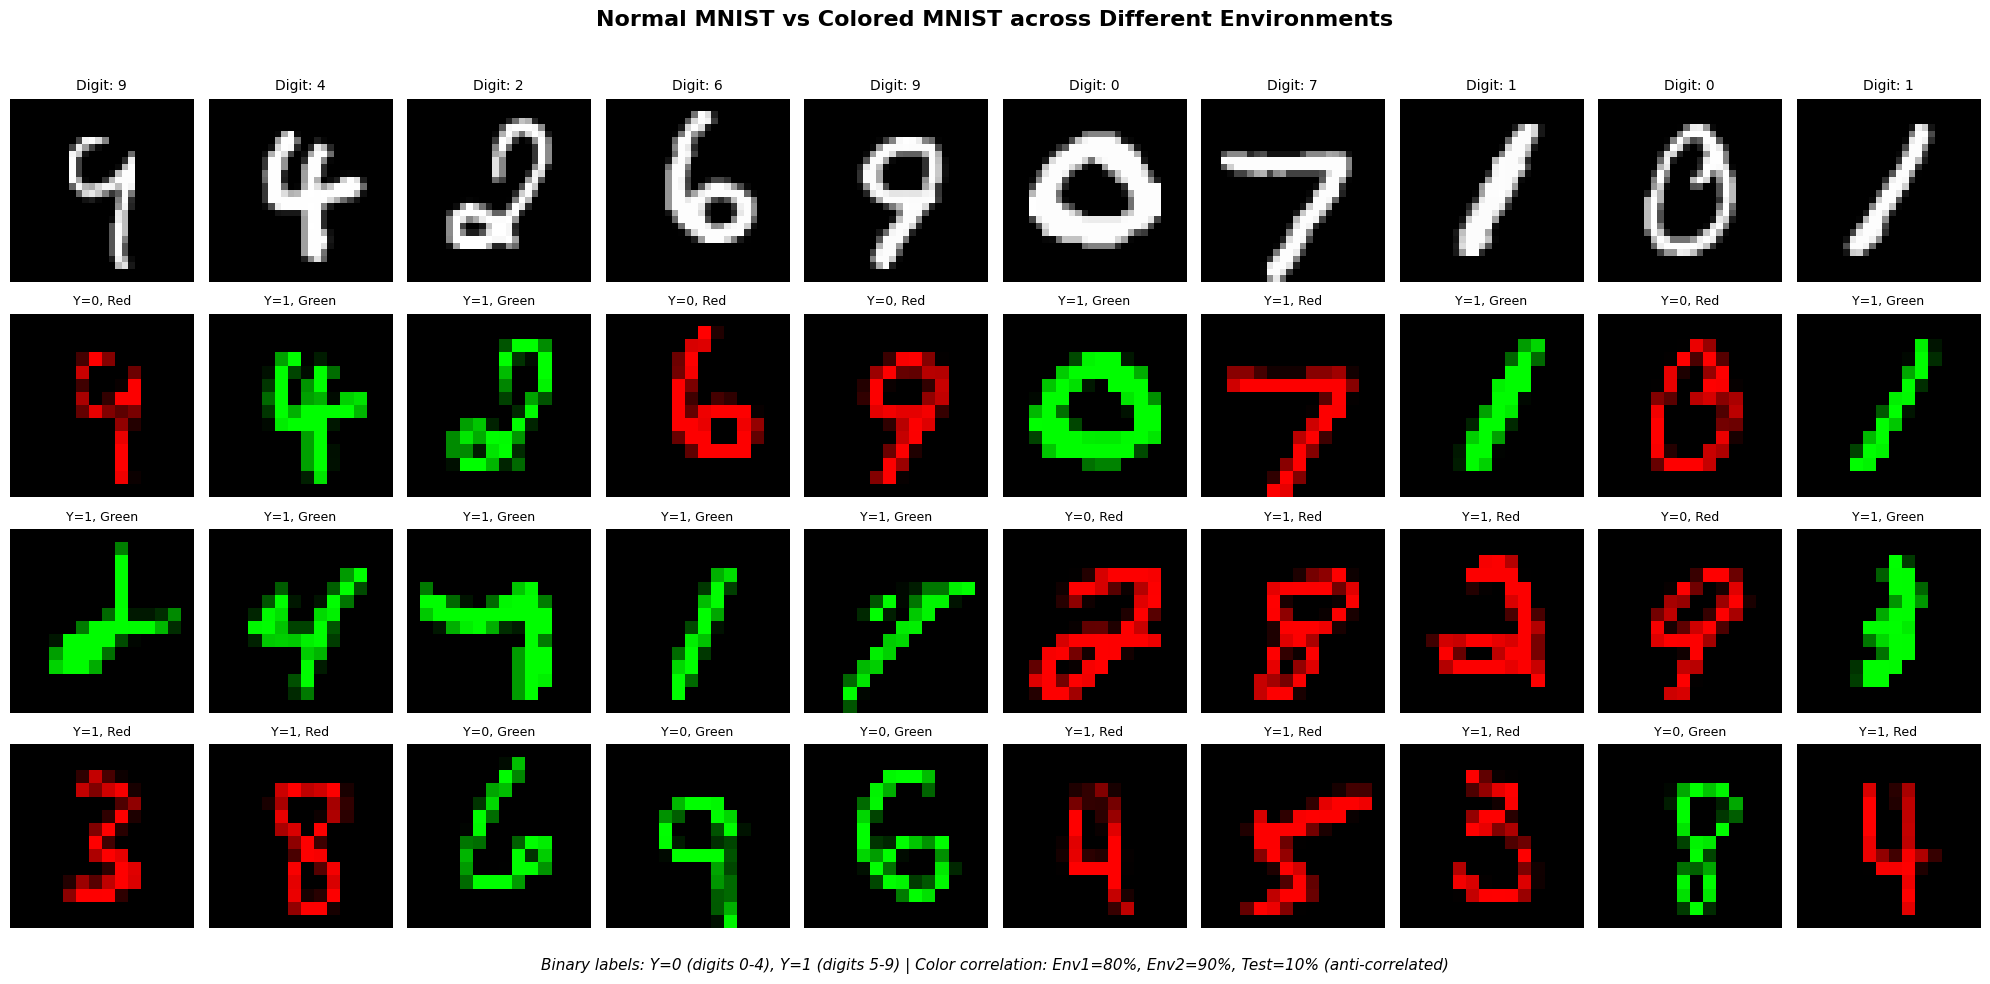

Computing correlation statistics...


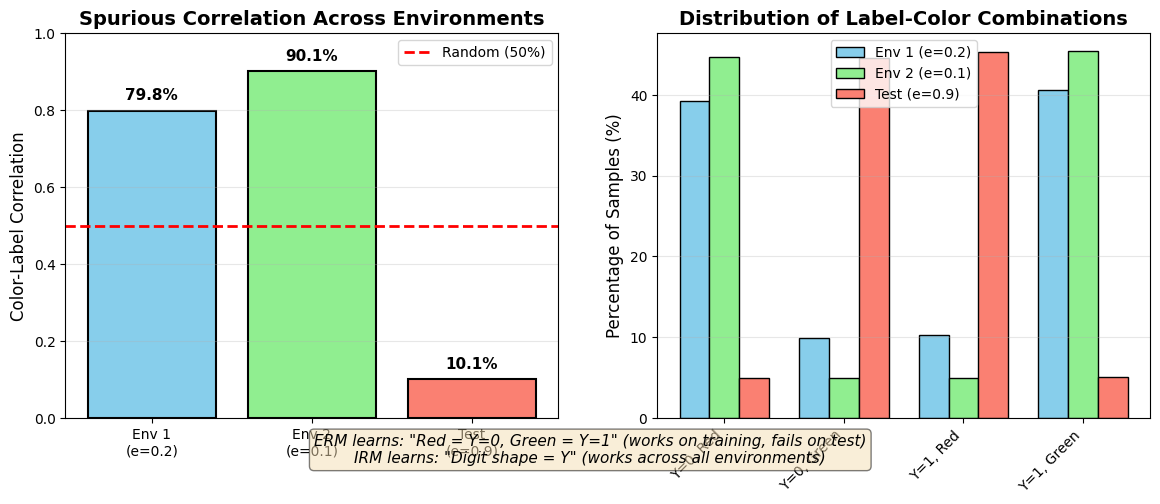

Spurious Correlations:
Environment 1 (e=0.2): 79.8% color-label correlation
Environment 2 (e=0.1): 90.1% color-label correlation
Test (e=0.9):          10.1% color-label correlation


In [34]:
visualize_colored_mnist()
visualize_spurious_correlation()